# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [6]:
!pip install yfinance

import yfinance as yf
import pandas as pd
tickers = ["CVX","CAT","PEP"]
start_date = "2024-01-01"
end_date = "2026-01-02"

for ticker in tickers:
    data = yf.download(
        ticker,
        start=start_date,
        end=end_date,
        auto_adjust=False
    )
    print(f"\nDatos históricos de {ticker}:")
    print(data.head())
    data.to_csv(f"{ticker}_historico.csv")
    print(f"Archivo guardado: {ticker}_historico.csv")


[*********************100%***********************]  1 of 1 completed



Datos históricos de CVX:
Price        Adj Close       Close        High         Low        Open  \
Ticker             CVX         CVX         CVX         CVX         CVX   
Date                                                                     
2024-01-02  133.236755  149.479996  151.479996  149.240005  149.990005   
2024-01-03  135.777054  152.330002  153.190002  148.679993  149.389999   
2024-01-04  134.288513  150.660004  154.350006  150.589996  153.660004   
2024-01-05  134.056763  150.399994  152.029999  149.830002  151.979996   
2024-01-08  133.254578  149.500000  149.699997  146.580002  148.419998   

Price         Volume  
Ticker           CVX  
Date                  
2024-01-02   8879700  
2024-01-03  10255300  
2024-01-04   8220300  
2024-01-05   7455400  
2024-01-08  10038200  
Archivo guardado: CVX_historico.csv


[*********************100%***********************]  1 of 1 completed



Datos históricos de CAT:
Price        Adj Close       Close        High         Low        Open  \
Ticker             CAT         CAT         CAT         CAT         CAT   
Date                                                                     
2024-01-02  282.079865  292.709991  296.640015  291.350006  293.429993   
2024-01-03  273.975311  284.299988  288.929993  283.320007  288.390015   
2024-01-04  275.709869  286.100006  288.220001  283.790009  284.410004   
2024-01-05  278.437134  288.929993  291.000000  285.470001  286.250000   
2024-01-08  281.636597  292.250000  292.679993  285.239990  287.559998   

Price        Volume  
Ticker          CAT  
Date                 
2024-01-02  2433100  
2024-01-03  3043400  
2024-01-04  2995400  
2024-01-05  2684800  
2024-01-08  2369100  
Archivo guardado: CAT_historico.csv


[*********************100%***********************]  1 of 1 completed


Datos históricos de PEP:
Price        Adj Close       Close        High         Low        Open  \
Ticker             PEP         PEP         PEP         PEP         PEP   
Date                                                                     
2024-01-02  156.347336  172.910004  172.990005  169.190002  169.520004   
2024-01-03  156.383469  172.949997  175.199997  172.699997  175.000000   
2024-01-04  155.045212  171.470001  173.529999  170.580002  171.610001   
2024-01-05  152.757584  168.940002  171.570007  167.559998  171.570007   
2024-01-08  152.911285  169.110001  169.729996  167.789993  168.940002   

Price        Volume  
Ticker          PEP  
Date                 
2024-01-02  5743100  
2024-01-03  5588200  
2024-01-04  6283200  
2024-01-05  5252500  
2024-01-08  5735600  
Archivo guardado: PEP_historico.csv


## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

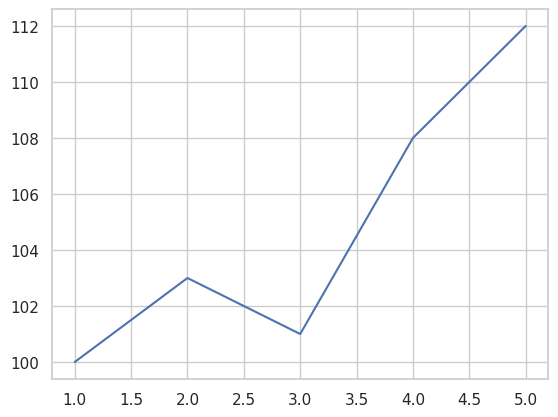

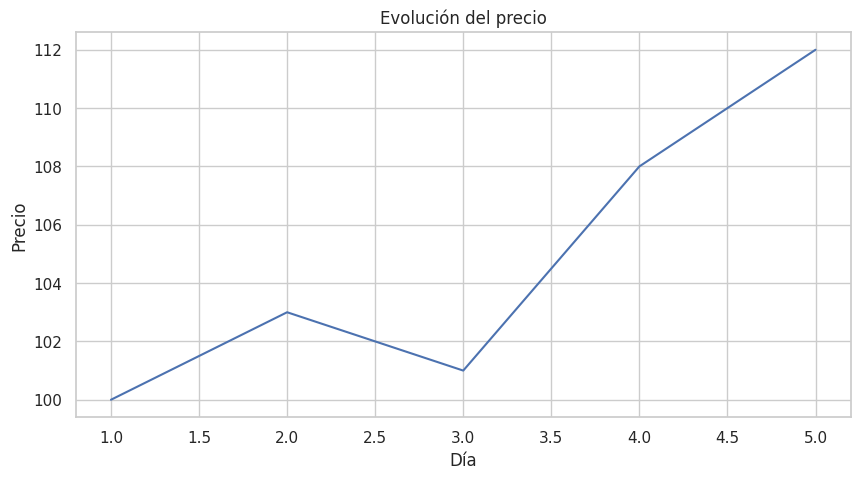

In [7]:
# Importamos las librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual básica
sns.set_theme(style="whitegrid")

# Para que los gráficos aparezcan dentro del notebook
%matplotlib inline
import matplotlib.pyplot as plt

dias = [1, 2, 3, 4, 5]
precios = [100, 103, 101, 108, 112]

datos_ejemplo = pd.DataFrame({
    "Día": dias,
    "Precio": precios
})

plt.plot(dias, precios)
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(dias, precios)

plt.title("Evolución del precio")
plt.xlabel("Día")
plt.ylabel("Precio")

plt.show()

## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

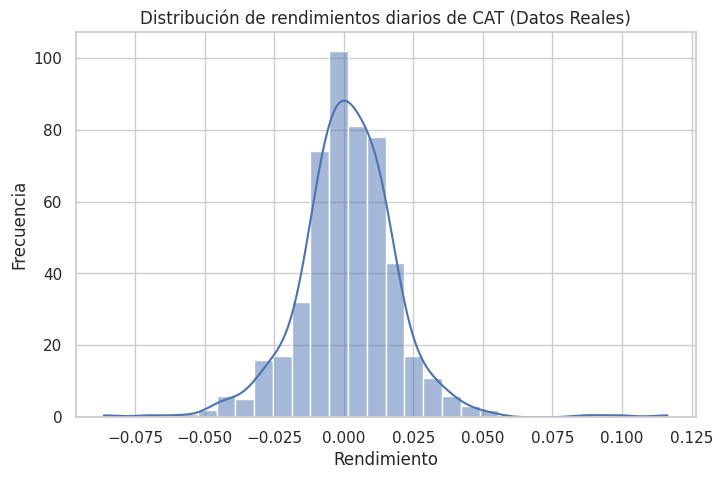

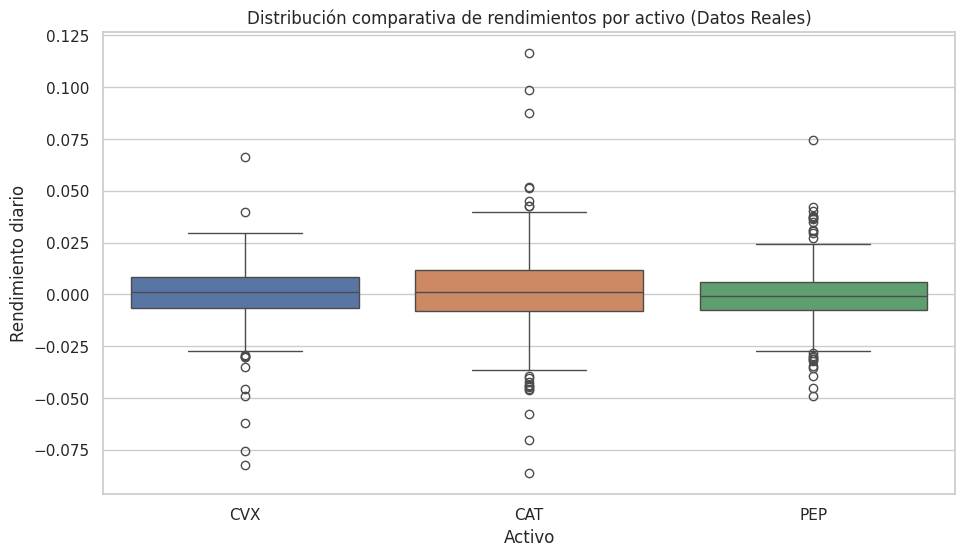

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. Cargar datos reales y calcular rendimientos
# ==========================================
tickers = ["CVX", "CAT", "PEP"]
precios_lista = []

for ticker in tickers:
    # Leemos especificando que las primeras dos filas (0 y 1) son los encabezados debido a la estructura de yfinance
    df = pd.read_csv(f"{ticker}_historico.csv", header=[0, 1], index_col=0, parse_dates=True)

    # Buscamos la columna de precios de cierre 'Close'
    if 'Close' in df.columns.levels[0]:
        serie_precio = df['Close'][ticker]
        precios_lista.append(serie_precio.rename(ticker))

# Concatenamos los precios de todos los activos en un único DataFrame
precios_reales = pd.concat(precios_lista, axis=1)

# Calculamos los rendimientos porcentuales diarios y eliminamos la primera fila nula
rendimientos = precios_reales.pct_change().dropna()

# ==========================================
# 2. Distribución y Visualización
# ==========================================
# Histograma del activo seleccionado (por ejemplo, CAT)
plt.figure(figsize=(8, 5))
sns.histplot(
    rendimientos["CAT"],
    bins=30,
    kde=True
)

plt.title("Distribución de rendimientos diarios de CAT (Datos Reales)")
plt.xlabel("Rendimiento")
plt.ylabel("Frecuencia")
plt.show()

# Boxplot comparativo de los 3 activos utilizando la variable 'rendimientos'
plt.figure(figsize=(11, 6))
sns.boxplot(data=rendimientos)

plt.title("Distribución comparativa de rendimientos por activo (Datos Reales)")
plt.xlabel("Activo")
plt.ylabel("Rendimiento diario")
plt.show()

## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

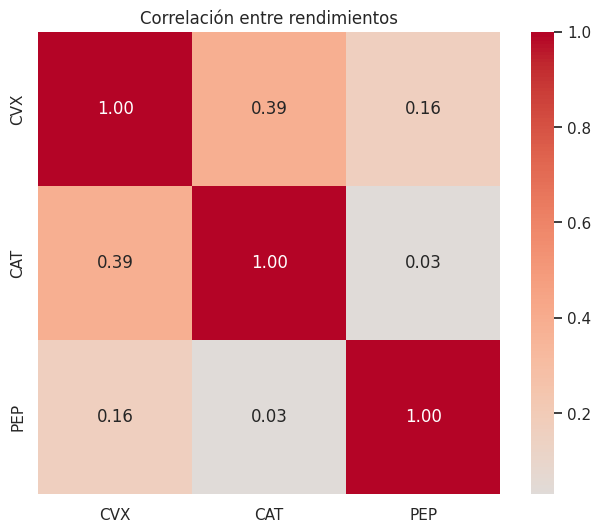

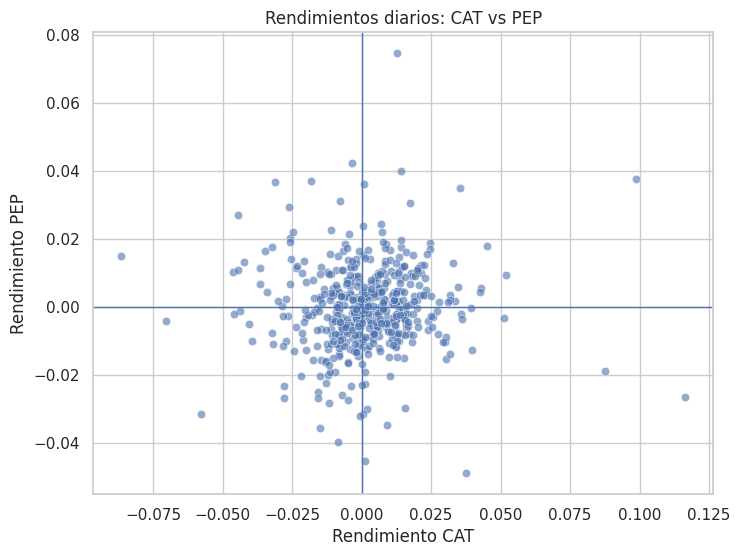

In [12]:
correlacion = rendimientos.corr()

correlacion
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlación entre rendimientos")

plt.show()
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=rendimientos,
    x="CAT",
    y="PEP",
    alpha=0.6
)

plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)

plt.title("Rendimientos diarios: CAT vs PEP")
plt.xlabel("Rendimiento CAT")
plt.ylabel("Rendimiento PEP")

plt.show()



## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [17]:
import yfinance as yf
import pandas as pd
tickers = ["CVX", "CAT", "PEP"]
datos = yf.download(
    tickers,
    start="2024-01-01",
    end="2026-01-02",
    auto_adjust=False)
precios = datos["Adj Close"]
rendimientos = precios.pct_change().dropna()
resumen = pd.DataFrame({
    "Media": rendimientos.mean(),
    "Mediana": rendimientos.median(),
    "Desviación Estándar": rendimientos.std(),
    "Mínimo": rendimientos.min(),
    "Máximo": rendimientos.max()
})
resumen_porcentual = resumen * 100
print("Resumen estadístico de los rendimientos diarios (%)")
print(resumen_porcentual.round(4))
resumen_porcentual.to_csv("resumen_estadistico.csv")



[*********************100%***********************]  3 of 3 completed

Resumen estadístico de los rendimientos diarios (%)
         Media  Mediana  Desviación Estándar  Mínimo   Máximo
Ticker                                                       
CAT     0.1570   0.1136               1.8367 -8.6356  11.6346
CVX     0.0309   0.1183               1.3784 -8.2244   6.6457
PEP    -0.0154  -0.0538               1.2438 -4.8854   7.4547


En conclusión, el análisis de los activos CVX, CAT y PEP permite comparar sus rendimientos y riesgos durante el periodo estudiado. La media muestra el rendimiento promedio, mientras que la desviación estándar indica qué tanto varían los precios. Esta información ayuda a identificar qué activo podría ser más conveniente para invertir, teniendo en cuenta que un mayor rendimiento también puede implicar un mayor riesgo y que los resultados pasados no garantizan ganancias futuras.